<a href="https://colab.research.google.com/github/aakashkumar089/Class-notes/blob/main/ots_cnn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import keras
from keras import layers


In [ ]:
# Model / data parameters
num_classes = 10
input_shape = (28, 28, 1)

# Load the data and split it between train and test sets
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

# Scale images to the [0, 1] range
x_train = x_train.astype("float32") / 255
x_test = x_test.astype("float32") / 255
# Make sure images have shape (28, 28, 1)
x_train = np.expand_dims(x_train, -1)
x_test = np.expand_dims(x_test, -1)
print("x_train shape:", x_train.shape)
print(x_train.shape[0], "train samples")
print(x_test.shape[0], "test samples")


# convert class vectors to binary class matrices
y_train = keras.utils.to_categorical(y_train, num_classes)
y_test = keras.utils.to_categorical(y_test, num_classes)


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
x_train shape: (60000, 28, 28, 1)
60000 train samples
10000 test samples


In [ ]:
model = keras.Sequential(
    [
        keras.Input(shape=input_shape),
        layers.Conv2D(32, kernel_size=(3, 3), activation="relu"),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Conv2D(64, kernel_size=(3, 3), activation="relu"),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Flatten(),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation="softmax"),
    ]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        16,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,826 (136.04 KB)

 Trainable params: 34,826 (136.04 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
batch_size = 128
epochs = 15

model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

history = model.fit(x_train, y_train, batch_size=batch_size, epochs=epochs, validation_split=0.1)

Epoch 1/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 48s 111ms/step - accuracy: 0.9901 - loss: 0.0308 - val_accuracy: 0.9920 - val_loss: 0.0305
Epoch 2/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 41s 97ms/step - accuracy: 0.9898 - loss: 0.0303 - val_accuracy: 0.9920 - val_loss: 0.0272
Epoch 3/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 47s 110ms/step - accuracy: 0.9903 - loss: 0.0303 - val_accuracy: 0.9920 - val_loss: 0.0307
Epoch 4/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 41s 98ms/step - accuracy: 0.9908 - loss: 0.0282 - val_accuracy: 0.9927 - val_loss: 0.0280
Epoch 5/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 53s 126ms/step - accuracy: 0.9908 - loss: 0.0267 - val_accuracy: 0.9928 - val_loss: 0.0279
Epoch 6/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 72s 102ms/step - accuracy: 0.9914 - loss: 0.0259 - val_accuracy: 0.9928 - val_loss: 0.0275
Epoch 7/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 79s 95ms/step - accuracy: 0.9909 - loss: 0.0262 - val_accuracy: 0.9925 - val_loss: 0.0317
Epoch 8/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 97ms/step - accuracy: 0.9915 - loss: 0.025

In [ ]:
# 2. Evaluate on unseen test data
score = model.evaluate(x_test, y_test, verbose=1)
print("Test loss:", score[0])
print("Test accuracy:", score[1])


# verbose=0: silent, nothing printed.
# verbose=1: progress bar with the running loss and metrics (the default for fit).
# verbose=2: one line per epoch, with no progress bar.


313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.9923 - loss: 0.0247
Test loss: 0.024702860042452812
Test accuracy: 0.9922999739646912


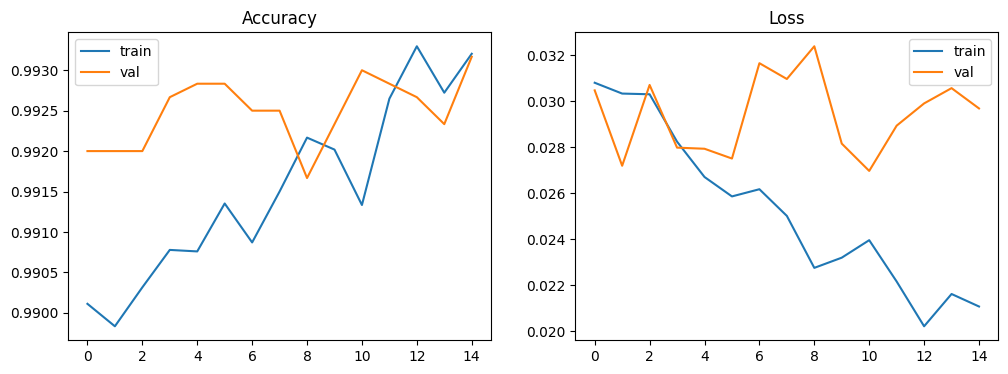

In [ ]:
## Plot accuracy and loss curves
# 3. Plot accuracy and loss curves to check for overfitting
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history["accuracy"], label="train")
ax[0].plot(history.history["val_accuracy"], label="val")
ax[0].set_title("Accuracy"); ax[0].legend()
ax[1].plot(history.history["loss"], label="train")
ax[1].plot(history.history["val_loss"], label="val")
ax[1].set_title("Loss"); ax[1].legend()
plt.show()


In [ ]:
# 4. Predictions and class labels
y_pred = np.argmax(model.predict(x_test), axis=1)
y_true = np.argmax(y_test, axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step


In [ ]:
# 5. Confusion matrix and per-class report
from sklearn.metrics import classification_report, confusion_matrix
print(confusion_matrix(y_true, y_pred))
print(classification_report(y_true, y_pred))


[[ 977    1    0    1    0    0    0    0    1    0]
 [   0 1129    3    2    0    0    1    0    0    0]
 [   1    1 1028    0    0    0    0    2    0    0]
 [   0    0    1 1005    0    3    0    0    1    0]
 [   0    0    0    0  978    0    1    1    1    1]
 [   0    0    0    6    0  885    1    0    0    0]
 [   3    3    1    0    1    2  946    0    2    0]
 [   0    4    8    1    0    1    0 1012    1    1]
 [   1    0    1    1    0    1    0    0  969    1]
 [   0    0    0    1    4    5    0    3    2  994]]
              precision    recall  f1-score   support

           0       0.99      1.00      1.00       980
           1       0.99      0.99      0.99      1135
           2       0.99      1.00      0.99      1032
           3       0.99      1.00      0.99      1010
           4       0.99      1.00      1.00       982
           5       0.99      0.99      0.99       892
           6       1.00      0.99      0.99       958
           7       0.99      0.98   

In [ ]:
# 6. Save the model
model.save("model.keras")